# 3. Temporal alignment

Does each detector report the action unit at the right time?

Classification metrics are blind to timing: a detector that reports the
right action unit a second late scores the same as one that reports it
on the frame. This notebook cross-correlates each detector's output
with the rig ground truth and takes the value at lag zero, which for
traces of equal length is Pearson's r between them.

Each video's matrix is flattened with each action unit's time course
kept contiguous, so the lags of the correlation are over time within an
action unit. Only OpenFace and AFAR are compared here, since py-feat's
near-constant detections leave nothing to align.

Produces Figure 3.

In [1]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

from au_detection_mh import analyses, utils

DATASET = os.path.join("..", "ds-au_detection_mh")
SOURCEDATA = os.path.join(DATASET, "sourcedata")
LANDMARKS = os.path.join(DATASET, "derivatives", "landmark-displacement")
RESULTS = os.path.join(DATASET, "derivatives", "au-detection-metrics")

# Activation above which a cell of the rig ground truth counts as an
# active action unit, and above which a detector counts as reporting
# one.  0.2 is the value the reported results use.
THRESHOLD = 0.2

# Avatar order used in the figures, which groups the two avatars the
# detectors did best on next to each other.
AVATAR_ORDER = ["Ada", "Pia", "Cooper", "Garry"]

# Manuscript figure styling
LABEL_FONTSIZE = 12
TICK_FONTSIZE = 10
DPI = 500
mpl.rcParams["font.size"] = 10

## Cross-correlating every video

`cross_correlation_table` returns one row per video with one column per
detector. `cross_correlation_profile` gives the same comparison across
lags, which is what the single lag-zero value is taken from.

In [2]:
DETECTOR_PAIR = ("OF", "AFAR")
cross_corr_df = analyses.cross_correlation_table(
    SOURCEDATA, detectors=DETECTOR_PAIR)
cross_corr_df.head()

,Avatar,Animation,crosscorr_0_act-OF,crosscorr_0_act-AFAR
0,Ada,AU01,0.816972,0.898301
1,Ada,AU02,0.090104,-0.102734
2,Ada,AU04,-0.081241,-0.081846
3,Ada,AU06,-0.108906,-0.095635
4,Ada,AU07,0.908708,0.158037


### The full lag profile, for one video

The reported number is the value at lag zero, marked below. The profile
is shown to make clear what that one value is a slice of.

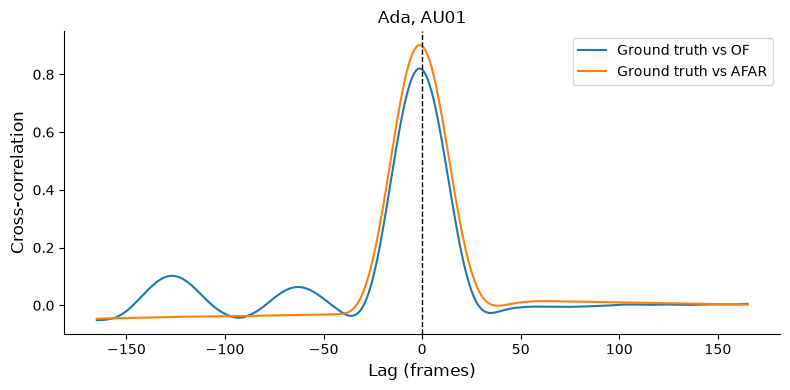

In [3]:
video = utils.load_video(SOURCEDATA, "Ada", "AU01",
                         sources=("actual", "OF", "AFAR"))

fig, ax = plt.subplots(figsize=(8, 4))
for detector in DETECTOR_PAIR:
    lags, correlation = analyses.cross_correlation_profile(
        video["actual"], video[detector])
    ax.plot(lags, correlation, label=f"Ground truth vs {detector}")
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("Lag (frames)", fontsize=LABEL_FONTSIZE)
ax.set_ylabel("Cross-correlation", fontsize=LABEL_FONTSIZE)
ax.set_title("Ada, AU01", fontsize=LABEL_FONTSIZE)
ax.legend()
sns.despine()
fig.tight_layout()
plt.show()

## Descriptive statistics

In [4]:
value_columns = [f"crosscorr_0_act-{d}" for d in DETECTOR_PAIR]
for column in value_columns:
    cross_corr_df[column] = cross_corr_df[column].astype(float)
for column in ["Avatar", "Animation"]:
    cross_corr_df[column] = cross_corr_df[column].astype("category")

cross_corr_df.groupby("Animation", observed=True)[value_columns].describe()

crosscorr_0_act-OF                                          \
                       count      mean       std       min       25%   
Animation                                                              
AU01                     4.0  0.489699  0.267165  0.244796  0.286779   
AU02                     4.0 -0.004488  0.073545 -0.070961 -0.057981   
AU04                     4.0  0.250224  0.357066 -0.081241 -0.042908   
AU06                     4.0 -0.116317  0.019726 -0.140686 -0.126318   
AU07                     4.0  0.876190  0.051932  0.800538  0.863115   
AU10                     4.0  0.623853  0.116049  0.511393  0.531870   
AU12                     4.0  0.454117  0.032130  0.429785  0.432361   
AU14                     4.0  0.612565  0.185413  0.440705  0.511094   
AU15                     4.0  0.188407  0.247171 -0.005554 -0.000953   
AU17                     4.0  0.218994  0.449842 -0.065557  0.001111   
AU23                     4.0  0.003524  0.153057 -0.095179 -0.079870   
browsAU10                4.0  0.527073  0.038703  0.499447  0.502704   
browsAU12                4.0  0.307513  0.045477  0.243351  0.294051   
browsAU14                4.0  0.503993  0.099282  0.412079  0.449068   
browsAU15                4.0  0.379085  0.076980  0.313834  0.314687   
browsAU17                4.0  0.417298  0.105976  0.307070  0.336510   
browsAU23                4.0  0.297580  0.083103  0.216099  0.230892   
browsAll                 4.0  0.443065  0.093246  0.331339  0.387104   

                                        crosscorr_0_act-AFAR            \
                50%       75%       max                count      mean   
Animation                                                                
AU01       0.448513  0.651432  0.816972                  4.0  0.535814   
AU02      -0.018547  0.034946  0.090104                  4.0  0.079265   
AU04       0.233717  0.526849  0.614700                  4.0  0.304650   
AU06      -0.115217 -0.105216 -0.094148                  4.0 -0.129121   
AU07       0.896341  0.909416  0.911538                  4.0  0.223475   
AU10       0.619629  0.711612  0.744763                  4.0  0.058181   
AU12       0.443543  0.465299  0.499595                  4.0  0.116744   
AU14       0.568672  0.670143  0.872212                  4.0  0.504344   
AU15       0.121476  0.310836  0.516231                  4.0  0.305186   
AU17       0.025428  0.243311  0.890678                  4.0 -0.020394   
AU23      -0.060966  0.022428  0.231205                  4.0  0.696844   
browsAU10  0.512777  0.537146  0.583289                  4.0  0.203480   
browsAU12  0.319025  0.332486  0.348650                  4.0  0.030235   
browsAU14  0.480507  0.535432  0.642878                  4.0  0.370903   
browsAU15  0.367957  0.432355  0.466592                  4.0  0.359973   
browsAU17  0.423792  0.504579  0.514537                  4.0  0.201535   
browsAU23  0.301574  0.368261  0.371072                  4.0  0.500428   
browsAll   0.449981  0.505942  0.540957                  4.0  0.330685   

                                                                       
                std       min       25%       50%       75%       max  
Animation                                                              
AU01       0.508472 -0.115036  0.256832  0.639544  0.918527  0.979205  
AU02       0.278996 -0.127523 -0.108931 -0.015814  0.172382  0.476209  
AU04       0.465408 -0.112994 -0.089633  0.294116  0.688400  0.743364  
AU06       0.031584 -0.170497 -0.142510 -0.125176 -0.111788 -0.095635  
AU07       0.347576 -0.102241  0.066526  0.140409  0.297359  0.715323  
AU10       0.288600 -0.135770 -0.101017 -0.058751  0.100447  0.485995  
AU12       0.225773 -0.142164 -0.036052  0.139437  0.292232  0.330266  
AU14       0.118140  0.380571  0.457598  0.485837  0.532583  0.665134  
AU15       0.424108 -0.055669 -0.033065  0.225488  0.563740  0.825438  
AU17       0.132196 -0.100189 -0.088406 -0.079318 -0.011307  0.177249  
AU23  

In [5]:
cross_corr_df.groupby("Avatar", observed=True)[value_columns].describe()

crosscorr_0_act-OF                                                    \
                    count      mean       std       min       25%       50%   
Avatar                                                                        
Ada                  18.0  0.482060  0.311421 -0.108906  0.325045  0.497765   
Cooper               18.0  0.296045  0.271652 -0.121528  0.054790  0.347486   
Garry                18.0  0.360858  0.276135 -0.140686  0.102416  0.466418   
Pia                  18.0  0.299342  0.278511 -0.094148  0.071525  0.303922   

                           crosscorr_0_act-AFAR                                \
             75%       max                count      mean       std       min   
Avatar                                                                          
Ada     0.719292  0.908708                 18.0  0.200869  0.328600 -0.102734   
Cooper  0.483351  0.883974                 18.0  0.321655  0.322732 -0.170497   
Garry   0.531359  0.800538                 18.0  0.239005  0.292959 -0.142164   
Pia     0.459515  0.911538                 18.0  0.276743  0.339582 -0.117172   

                                                
             25%       50%       75%       max  
Avatar                                          
Ada    -0.050436  0.072262  0.324754  0.923722  
Cooper  0.031644  0.372826  0.564232  0.825438  
Garry  -0.071670  0.241366  0.479576  0.743364  
Pia    -0.003241  0.297757  0.417954  0.979205

### Long form

One row per video and detector, which is the shape the tests and the
figures below want.

In [6]:
crosscorr_long_df = pd.melt(
    cross_corr_df, value_vars=value_columns,
    value_name="Cross-correlation", var_name="comparison")
crosscorr_long_df["Avatar"] = np.tile(cross_corr_df["Avatar"].values, 2)
crosscorr_long_df["Animation"] = np.tile(
    cross_corr_df["Animation"].values, 2)
crosscorr_long_df.to_csv(os.path.join(RESULTS, "crosscorr_long_df.csv"))
crosscorr_long_df.head()

,comparison,Cross-correlation,Avatar,Animation
0,crosscorr_0_act-OF,0.816972,Ada,AU01
1,crosscorr_0_act-OF,0.090104,Ada,AU02
2,crosscorr_0_act-OF,-0.081241,Ada,AU04
3,crosscorr_0_act-OF,-0.108906,Ada,AU06
4,crosscorr_0_act-OF,0.908708,Ada,AU07


### Checking the normality assumption

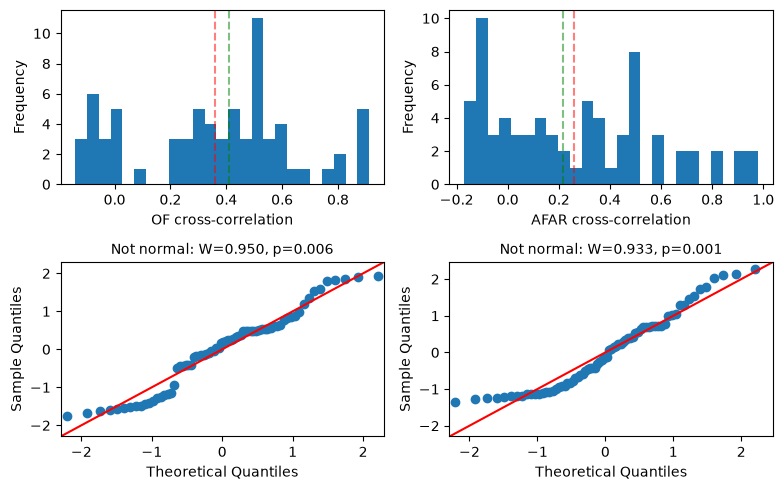

In [7]:
from scipy.stats import shapiro

ALPHA = 0.05
fig, axs = plt.subplots(2, 2, figsize=(8, 5))
for column, detector in enumerate(DETECTOR_PAIR):
    key = f"crosscorr_0_act-{detector}"
    values = crosscorr_long_df[
        crosscorr_long_df["comparison"] == key][
            "Cross-correlation"].to_numpy()

    counts, bins = np.histogram(values, bins=25)
    axs[0, column].hist(values, bins=25)
    axs[0, column].set_xlabel(f"{detector} cross-correlation")
    axs[0, column].set_ylabel("Frequency")
    axs[0, column].axvline(np.mean(values), linestyle="dashed",
                           color="red", alpha=0.5)
    axs[0, column].axvline(np.median(values), linestyle="dashed",
                           color="green", alpha=0.5)

    import statsmodels.api as sm
    standardised = (values - np.mean(values)) / np.std(values)
    sm.qqplot(standardised, line="45", ax=axs[1, column])
    statistic, p_value = shapiro(values)
    verdict = "Normal distribution" if p_value > ALPHA else "Not normal"
    axs[1, column].set_title(
        f"{verdict}: W={statistic:.3f}, p={p_value:.3f}",
        fontsize=TICK_FONTSIZE)

fig.tight_layout()
plt.show()

### Between-detector comparison

In [8]:
crosscorr_long_df.groupby("comparison")["Cross-correlation"].describe()

,count,mean,std,min,25%,50%,75%,max
comparison,,,,,,,,
crosscorr_0_act-AFAR,72.0,0.259568,0.317783,-0.170497,-0.029737,0.216349,0.481267,0.979205
crosscorr_0_act-OF,72.0,0.359576,0.288907,-0.140686,0.184600,0.408886,0.517614,0.911538


In [9]:
scores_of = crosscorr_long_df[
    crosscorr_long_df["comparison"] == "crosscorr_0_act-OF"][
        "Cross-correlation"].values
scores_afar = crosscorr_long_df[
    crosscorr_long_df["comparison"] == "crosscorr_0_act-AFAR"][
        "Cross-correlation"].values
pg.wilcoxon(scores_of, scores_afar)

,W_val,alternative,p_val,RBC,CLES
Wilcoxon,895.0,two-sided,0.01885,0.318874,0.607253


### Within-factor comparisons

In [10]:
def friedman_within(data, dv, within, subject, label):
    result = pg.friedman(data=data, dv=dv, within=within,
                         subject=subject)
    corrected = 0.05 / len(data[within].unique())
    print(f"Friedman's test for {label} across {within}:")
    print(result)
    print(f"Less than the corrected p-val (p/N = {corrected:.4f})? = "
          f"{result['p_unc'].values[0] < corrected}\n")
    return result


friedman_within(crosscorr_long_df, "Cross-correlation", "Avatar",
                "Animation", "cross-corr")

Friedman's test for cross-corr across Avatar:
          Source         W  ddof1         Q     p_unc
Friedman  Avatar  0.065432      3  3.533333  0.316465
Less than the corrected p-val (p/N = 0.0125)? = False



,Source,W,ddof1,Q,p_unc
Friedman,Avatar,0.065432,3,3.533333,0.316465


In [11]:
(crosscorr_long_df.groupby("Avatar", observed=True)["Cross-correlation"]
 .describe().sort_values(by="mean", ascending=False))

,count,mean,std,min,25%,50%,75%,max
Avatar,,,,,,,,
Ada,36.0,0.341464,0.346243,-0.108906,0.020572,0.320609,0.579766,0.923722
Cooper,36.0,0.308850,0.294282,-0.170497,-0.001068,0.356757,0.498036,0.883974
Garry,36.0,0.299932,0.287299,-0.142164,0.015892,0.427081,0.512179,0.800538
Pia,36.0,0.288042,0.306297,-0.117172,0.011118,0.303922,0.438250,0.979205


In [12]:
friedman_within(crosscorr_long_df, "Cross-correlation", "Animation",
                "Avatar", "cross-corr")

Friedman's test for cross-corr across Animation:
             Source        W  ddof1          Q     p_unc
Friedman  Animation  0.53225     17  36.192982  0.004322
Less than the corrected p-val (p/N = 0.0028)? = False



,Source,W,ddof1,Q,p_unc
Friedman,Animation,0.53225,17,36.192982,0.004322


In [13]:
(crosscorr_long_df.groupby("Animation", observed=True)["Cross-correlation"]
 .describe().sort_values(by="mean", ascending=False))

,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU14,8.0,0.558455,0.155117,0.380571,0.472631,0.511478,0.618374,0.872212
AU07,8.0,0.549832,0.417918,-0.102241,0.149223,0.757930,0.890157,0.911538
AU01,8.0,0.512757,0.376832,-0.115036,0.286779,0.488520,0.837304,0.979205
browsAU14,8.0,0.437448,0.108677,0.308219,0.356131,0.436738,0.485353,0.642878
browsAU23,8.0,0.399004,0.127678,0.216099,0.334449,0.400744,0.493746,0.578591
browsAll,8.0,0.386875,0.121876,0.211054,0.303915,0.419369,0.466316,0.540957
browsAU15,8.0,0.369529,0.197359,-0.034739,0.314687,0.368452,0.492463,0.588596
browsAU10,8.0,0.365276,0.195553,0.098872,0.175621,0.447576,0.508283,0.583289
AU23,8.0,0.350184,0.460506,-0.095179,-0.054065,0.175827,0.837162,0.934895


### Within-factor comparisons, one detector at a time

In [14]:
for detector in DETECTOR_PAIR:
    key = f"crosscorr_0_act-{detector}"
    subset = crosscorr_long_df[
        crosscorr_long_df["comparison"] == key].reset_index(drop=True)
    for within, subject in [("Avatar", "Animation"),
                            ("Animation", "Avatar")]:
        friedman_within(subset, "Cross-correlation", within, subject,
                        detector)

Friedman's test for OF across Avatar:
          Source         W  ddof1     Q     p_unc
Friedman  Avatar  0.222222      3  12.0  0.007383
Less than the corrected p-val (p/N = 0.0125)? = True

Friedman's test for OF across Animation:
             Source         W  ddof1          Q     p_unc
Friedman  Animation  0.732972     17  49.842105  0.000045
Less than the corrected p-val (p/N = 0.0028)? = True

Friedman's test for AFAR across Avatar:
          Source         W  ddof1    Q     p_unc
Friedman  Avatar  0.003704      3  0.2  0.977589
Less than the corrected p-val (p/N = 0.0125)? = False

Friedman's test for AFAR across Animation:
             Source         W  ddof1          Q     p_unc
Friedman  Animation  0.468266     17  31.842105  0.015742
Less than the corrected p-val (p/N = 0.0028)? = False



### Figure 3: cross-correlation heatmaps and barplots

The dashed line separates the 11 single-action-unit animations from the
7 brow combinations.

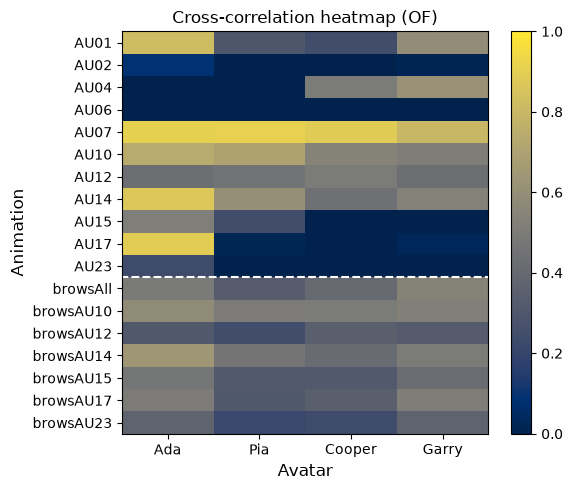

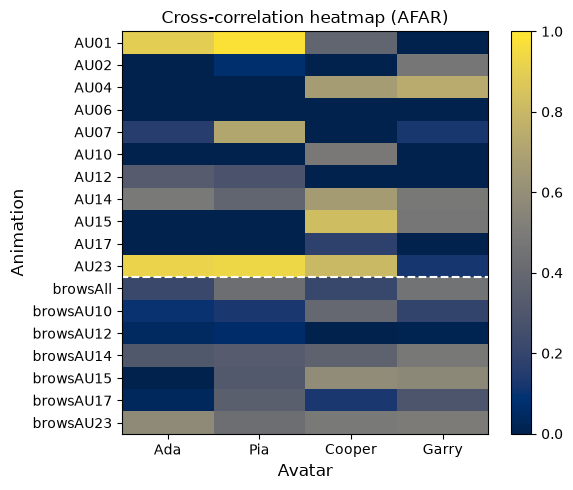

In [15]:
for detector in DETECTOR_PAIR:
    key = f"crosscorr_0_act-{detector}"
    heatmap = pd.pivot_table(cross_corr_df, values=key,
                             index="Animation", columns="Avatar",
                             observed=True)[AVATAR_ORDER]
    heatmap = heatmap.reindex(list(utils.ANIMATIONS))

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(heatmap.values.astype(float), aspect="auto",
                      cmap="cividis")
    ax.set_xticks(range(len(AVATAR_ORDER)))
    ax.set_xticklabels(AVATAR_ORDER, fontsize=TICK_FONTSIZE)
    ax.set_yticks(range(len(utils.ANIMATIONS)))
    ax.set_yticklabels(utils.ANIMATIONS, fontsize=TICK_FONTSIZE)
    ax.set_xlabel("Avatar", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Animation", fontsize=LABEL_FONTSIZE)
    ax.set_title(f"Cross-correlation heatmap ({detector})",
                 fontsize=LABEL_FONTSIZE)
    ax.grid(False)
    fig.colorbar(image, ax=ax)
    image.set_clim(0, 1)
    ax.axhline(y=10.5, xmin=-1, color="white", ls="--")
    fig.tight_layout()
    fig.savefig(
        os.path.join(RESULTS,
                     f"Figure3_{detector}_CrossCorr_heatmap.svg"),
        dpi=DPI)
    plt.show()

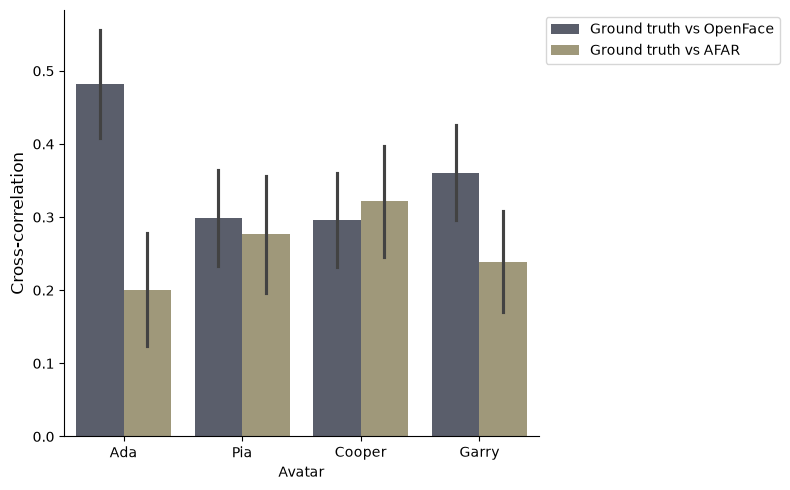

In [16]:
LEGEND_LABELS = {"crosscorr_0_act-OF": "Ground truth vs OpenFace",
                 "crosscorr_0_act-AFAR": "Ground truth vs AFAR"}


def crosscorr_barplot(x, figsize, filename, rotate_ticks=False):
    fig, ax = plt.subplots(figsize=figsize)
    order = AVATAR_ORDER if x == "Avatar" else None
    sns.barplot(crosscorr_long_df, x=x, y="Cross-correlation",
                hue="comparison", errorbar="se", ax=ax, order=order,
                palette="cividis")
    sns.despine()
    ax.set_ylabel("Cross-correlation", fontsize=LABEL_FONTSIZE)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [LEGEND_LABELS[label] for label in labels])
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    if rotate_ticks:
        plt.xticks(rotation=45)
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS, filename), dpi=DPI)
    plt.show()


crosscorr_barplot("Avatar", (8, 5), "Figure3C_barplot_err-se.svg")

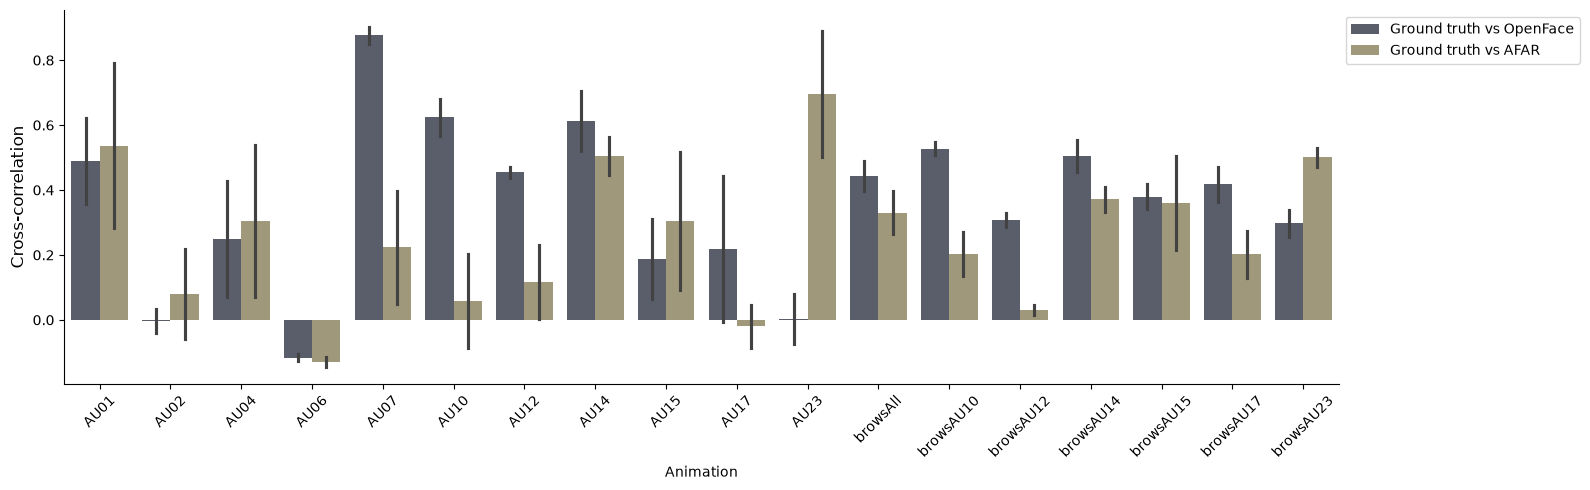

In [17]:
crosscorr_barplot("Animation", (16, 5), "Figure3D_barplot_err-se.svg",
                  rotate_ticks=True)